# Perturb demo B: an uncertainty budget for every data point

Gaussian perturbation explains a black-box's answer for a single sample. It nudges a small, smooth region of the input
up and down by a few times its noise, and records how the answer moves. Doing this at every position gives a map of
which parts of the input each output depends on, and in which direction.

In this demo we show how you can also read this map backwards! We want to constrain the amplitude $a_4$ to
$\pm 0.1$. What is the largest noise each data point of the instrument can have, so that no region of the
observation moves $a_4$ by more than that, and how many observations do we need to take with each 
instrument to get there?

The perturbation answers the first half of this directly. For a window centred on point $m$, the response
$\Delta a_4(\xi)$ tells us how far the answer moves when that region moves by $\xi$ times its noise. The first
magnitude $\xi_c$ at which $|\Delta a_4|$ reaches the target is how far the region can move before the answer moves
too much, so its noise can be at most $|\xi_c|\,\sigma_m$. Averaging $N$ exposures divides the noise by $\sqrt N$,
which answers the second half, as point $m$ then needs $N_m = \lceil 1/\xi_c^2 \rceil$ exposures.

**The problem.** A spectrum on a fine native grid $\lambda \in [0, 10]$ is set by 5 unknown amplitudes
$a_k \sim U(0.1, 2)$, each of which scales a fixed band shape $b_k(\lambda)$, and saturates where it is deep:

$$d(\lambda) = 1 - \exp\Big(-\sum_k a_k\, b_k(\lambda)\Big), \qquad b_k(\lambda) = \sum_j h_{kj}\, e^{-(\lambda-\mu_{kj})^2 / 2 s_{kj}^2}.$$

Every Gaussian has its own fixed width, so the bands overlap their neighbours by different amounts, and every
amplitude controls two or three Gaussians in different places. This means that neighbouring amplitudes are partly
degenerate, as more of one can be traded for less of another. A cloud deck also sets a floor on the depth, below
which the amplitudes have no effect.

**The instrumentation** sits side by side along $\lambda$, with 4 overlapping photometric **filters** (one point each,
each with its own noise), followed by two **spectrographs**, S1 and S2. Each of these six can be exposed as many times
as we like. The noise is only drawn once, so every plan sees the same noise realisation, scaled by $1/\sqrt N$.

**The black-box** is `scipy.optimize.least_squares`, fitting the forward model (averaged over each point's bandpass)
to one observation. It only fits one observation per call so we can use `Perturber(batch_size=1)`.

**The method** has four steps, followed by the budget itself:
1. `perturb.fit_kernel_width` finds the kernel width, i.e. how far apart two points can be and still move together.
2. `perturb.in_distribution_curve` finds how large a perturbation the retrieval can still handle the same way it
   handles a small one.
3. `perturb.Perturber` calculates the response of $f$ to every perturbation of the observation.
4. `perturb.plotting.callouts` plots the response against the target.
5. `PerturbResult.crossing` gives the noise budget of every point, and the number of exposures every instrument needs.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "uncertainty_budget")                       # the demo problem; `pip install -e ..` installs perturb itself
sys.path.insert(0, str(Path("..", "src").resolve()))  # ... or use it straight from the repo
import perturb as pt
from perturb import plotting
import instrument as ins

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
rng = np.random.default_rng(1)

## The available instrumentation

This is all the intrument modes we want to aquire observations with. The top panel shows the transmission of
each element. The 4 filters are treated as the spectrum averaged with its profile as the weight, placed at
the profile's effective wavelength (the square below). The two spectrographs have flat bins. The bottom panel
shows the noise of every data point, which ramps up logarithmically along each spectrograph.

84 points: 4 filters, 54 S1 bins, 26 S2 bins


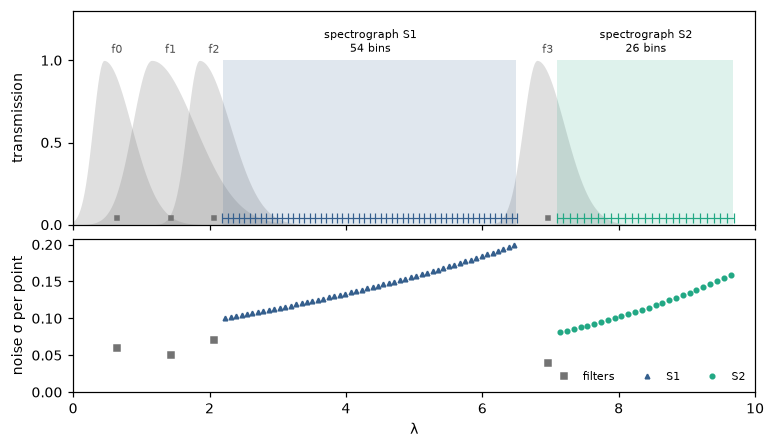

In [2]:
FILTER_C = "0.45"
SPEC_C = dict(zip(ins.SPECTROGRAPHS, plt.cm.viridis([0.3, 0.6])))
SPEC_M = dict(zip(ins.SPECTROGRAPHS, ["^", "o"]))   # S1 triangles, S2 dots, everywhere

def draw_bins(ax, name, e, y, h):
    # draw a spectrograph's bins at height y, as a line over its extent with a tick of half-height h at every bin
    # edge (merged bins have their edges further apart)
    dl = ins.LAM[1] - ins.LAM[0]
    x = ins.LAM[0] + (np.asarray(e) - 0.5) * dl            # edge between native pixels e - 1 and e
    ax.hlines(y, x[0], x[-1], color=SPEC_C[name], lw=0.8)
    ax.vlines(x, y - h, y + h, color=SPEC_C[name], lw=0.8)

def draw_filters(ax, filters, base=0, height=1, transform=None, **kw):
    # fill each selected filter's transmission profile from base up to base + height * profile
    for i in filters:
        prof = ins.FILTER_PROFILES[i]
        ax.fill_between(ins.LAM, base, base + height * prof, where=prof > 0, transform=transform or ax.transData,
                        color="0.5", alpha=0.25, lw=0, **kw)

def draw_instrument(ax, config, obs=None, spectrum=True, y=(0, 0.04)):
    # draw the true spectrum, the selected filters and spectrograph bins, and optionally an observation
    if spectrum:
        ax.plot(ins.LAM, ins.total_depth(A_TRUE), color="k", lw=1, label="true spectrum")
    draw_filters(ax, config["filters"], height=0.5, transform=ax.get_xaxis_transform())
    for name in ins.SPECTROGRAPHS:
        if config[name] is not None:
            e = config[name]
            draw_bins(ax, name, e, y[0], 0.02)
    if obs is not None:
        f = np.char.startswith(obs["element"], "f")
        ax.errorbar(obs["x_axis"][f], obs["y"][f], obs["sigma"][f], fmt="s", ms=4, color=FILTER_C, elinewidth=0.8,
                    label="filters")
        for name in ins.SPECTROGRAPHS:
            g = obs["element"] == name
            ax.errorbar(obs["x_axis"][g], obs["y"][g], obs["sigma"][g], fmt=SPEC_M[name], ms=3, color=SPEC_C[name],
                        elinewidth=0.6, label=name)
        ax.axhline(ins.CLOUD_DECK, color="0.5", lw=0.8, ls="--", label="cloud deck")

    ax.set_xlim(0, 10)

full = ins.full_config()
layout = ins.instrument(full)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1], hspace=0.08))
draw_filters(a1, full["filters"])
for i, c in enumerate(ins.FILTER_CENTRES):
    a1.text(c, 1.03, f"f{i}", ha="center", va="bottom", fontsize=7, color="0.3")
    a1.plot(c, 0.04, "s", color=FILTER_C, ms=3)
for name in ins.SPECTROGRAPHS:
    e = full[name]
    a1.fill_between([ins.LAM[e[0]], ins.LAM[e[-1] - 1]], 0, 1, color=SPEC_C[name], alpha=0.15, lw=0)
    draw_bins(a1, name, e, 0.04, 0.03)
    a1.text(ins.LAM[e[[0, -1]]].mean(), 1.03, f"spectrograph {name}\n{len(e) - 1} bins", ha="center", va="bottom", fontsize=7)
a1.set_ylim(0, 1.3); a1.set_yticks([0, 0.5, 1]); a1.set_ylabel("transmission")
f = np.char.startswith(layout["element"], "f")
a2.plot(layout["x_axis"][f], layout["sigma"][f], "s", color=FILTER_C, ms=4, label="filters")
for name in ins.SPECTROGRAPHS:
    g = layout["element"] == name
    a2.plot(layout["x_axis"][g], layout["sigma"][g], SPEC_M[name], color=SPEC_C[name], ms=3, label=name)
a2.set_ylim(0, None); a2.set_xlim(0, 10); a2.set_xlabel("λ"); a2.set_ylabel("noise σ per point")
a2.legend(fontsize=7, frameon=False, ncols=3, loc="lower right")
fig.align_ylabels([a1, a2])
print(f"{len(layout['x_axis'])} points: {len(full['filters'])} filters, "
      + ", ".join(f"{(layout['element'] == n).sum()} {n} bins" for n in ins.SPECTROGRAPHS))

## The parameters, and the sample

Let's fix the true amplitudes for our observation. The observation spectrum is set by 5 unknown amplitudes
$a_k \sim U(0.1, 2)$, each of which scales a fixed band shape $b_k(\lambda)$, and saturates where it is deep
in a cloud-like way.

The target parameter is $a_4$, which has one band at the red end of S1, next to filter f3, and
another in S2, so three instruments can see it. It is also degenerate with $a_3$ and $a_5$ on either side, so the data
that pins down its neighbours matters too.

The top panel shows the true spectrum, and the observation $x^\star$ that one exposure of every instrument makes of
it, which is the sample we want to explain. The bottom panel shows the same spectrum taken apart into the optical
depth each amplitude contributes on its own, $a_k b_k(\lambda)$, each drawn at its own height. Most points carry more
than one amplitude, and every amplitude shows up more than once.

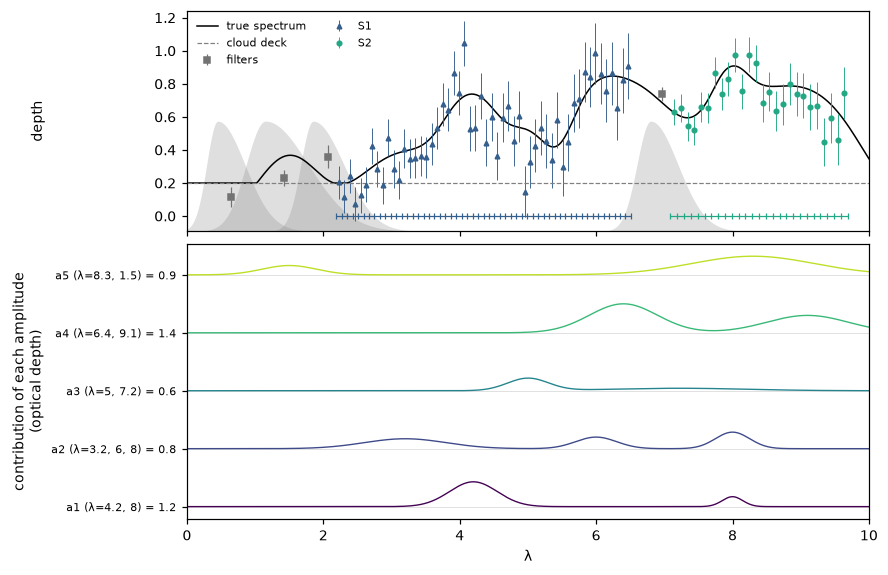

In [3]:
A_TRUE = np.array([1.2, 0.8, 0.6, 1.4, 0.9])
P = 3                                               # the parameter to constrain: a4
TARGET = 0.1                                        # ... to this 1 sigma
obs = ins.observe(full, A_TRUE)

fig, (ax, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=[1.2, 1.5], hspace=0.05))
draw_instrument(ax, full, obs)
ax.set_ylabel("depth"); ax.legend(fontsize=7, frameon=False, loc="upper left", ncols=2)
# the same spectrum taken apart into each amplitude's optical depth a_k b_k, drawn at its own height
spacing = 2 * ins.contribution(A_TRUE).max()
for k, (band, colour) in enumerate(zip(ins.contribution(A_TRUE), plt.cm.viridis(np.linspace(0, 0.9, len(ins.NAMES))))):
    a2.axhline(k, color="0.85", lw=0.5)
    a2.plot(ins.LAM, k + band / spacing, color=colour, lw=0.9)
a2.set_yticks(range(len(ins.NAMES)), [f"{n} = {a:g}" for n, a in zip(ins.NAMES, A_TRUE)], fontsize=7)
a2.set_xlabel("λ"); a2.set_ylabel("contribution of each amplitude\n(optical depth)")
fig.align_ylabels([ax, a2]);

## The black-box

`ins.retrieval(obs)` returns `f`, which takes observations $(N, M)$ and returns amplitudes $(N, P)$, running one
least-squares fit per row. This is all Perturb needs from a black-box. The observation itself is fitted from 8 random
starting points, and the best fit is kept. Every other row (i.e. every perturbed sample) is warm-started from that
solution, so that the perturbations are followed along the same branch rather than jumping between local minima.

The retrieved covariance comes from the fit's Jacobian and the prior, $(J^\top \Sigma^{-1} J + \Sigma_\text{prior}^{-1})^{-1}$.
On the left is the true spectrum (black), and the retrieved amplitudes put back through the forward model,
$g(f(x^\star))$ (red), with the 1σ spread of spectra drawn from that covariance shaded. On the right is a **corner
plot** of the posterior, taken as the Gaussian with that covariance. The diagonal shows the marginal of each
amplitude, and every other panel shows the joint posterior of a pair, as its 1σ ellipse (solid) and its 2σ ellipse
(dashed and lighter). The 1σ ellipse is the contour whose shadow on each axis is the ±1σ marginal, and the diagonal
shades ±1σ and ±2σ in the same way. The truth is marked by the black lines. Tilted ellipses show the degeneracies,
where more of one amplitude can be traded for less of another. One exposure of everything gives $a_4$ an error
bar of about twice the target.

a4 (λ=6.4, 9.1) = 1.518 ± 0.195 from one exposure; target ± 0.1


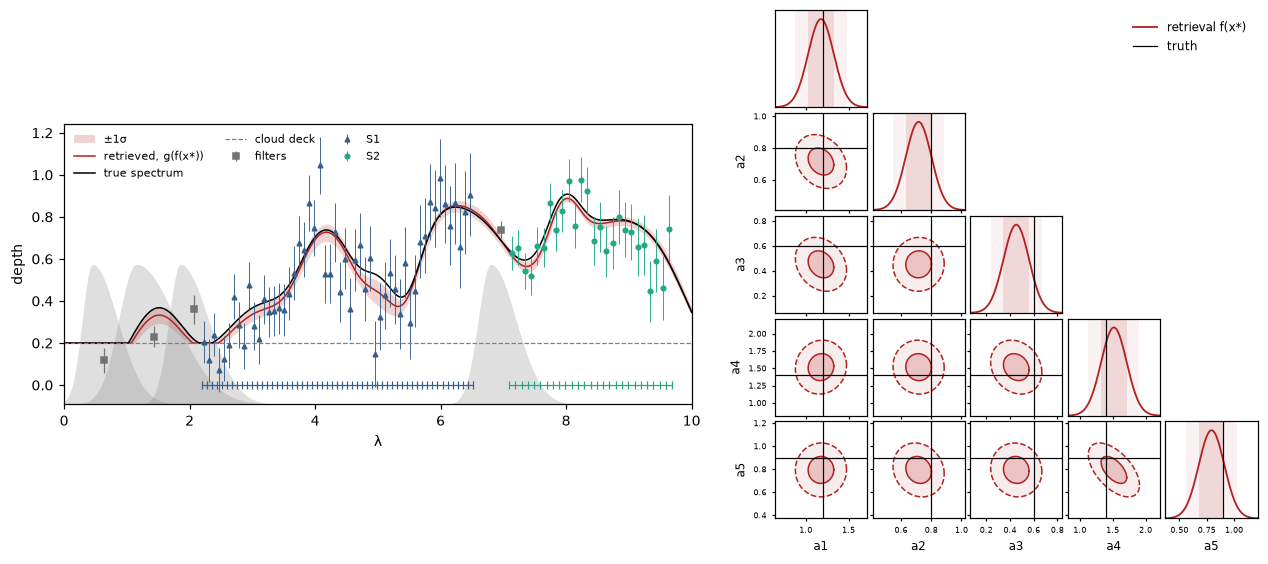

In [4]:
f = ins.retrieval(obs)
cov = ins.covariance(obs, f.best)
sig = np.sqrt(np.diag(cov))

def corner(fig, cell, entries, truth=A_TRUE):
    # a lower-triangle corner plot of Gaussian posteriors, where entries = [(label, mean, cov, colour), ...]
    P = len(truth)
    gs = cell.subgridspec(P, P, hspace=0.06, wspace=0.06)
    sd = [np.sqrt(np.diag(c)) for _, _, c, _ in entries]
    lo = np.min([m - 3 * s for (_, m, _, _), s in zip(entries, sd)] + [truth], axis=0)
    hi = np.max([m + 3 * s for (_, m, _, _), s in zip(entries, sd)] + [truth], axis=0)
    lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)
    t = np.linspace(0, 2 * np.pi, 100)
    for i in range(P):
        for j in range(i + 1):
            ax = fig.add_subplot(gs[i, j])
            for (label, m, c, colour), s in zip(entries, sd):
                if i == j:
                    x = np.linspace(lo[i], hi[i], 200)
                    ax.plot(x, np.exp(-0.5 * ((x - m[i]) / s[i]) ** 2), color=colour, lw=1.2, label=label)
                    for n, alpha in ((2, 0.06), (1, 0.12)):  # 2 sigma, then 1 sigma on top
                        ax.axvspan(m[i] - n * s[i], m[i] + n * s[i], color=colour, alpha=alpha, lw=0)
                else:
                    L = np.linalg.cholesky(c[np.ix_([j, i], [j, i])])
                    for n, alpha, ls in ((2, 0.08, "--"), (1, 0.2, "-")):  # 2 sigma, then 1 sigma on top
                        xy = m[[j, i], None] + n * L @ np.array([np.cos(t), np.sin(t)])
                        ax.fill(*xy, color=colour, alpha=alpha, lw=0)
                        ax.plot(*xy, color=colour, lw=1, ls=ls)
            ax.axvline(truth[j], color="k", lw=0.8)
            if i != j:
                ax.axhline(truth[i], color="k", lw=0.8)
                ax.set_ylim(lo[i], hi[i])
            else:
                ax.set_ylim(0, 1.1); ax.set_yticks([])
            ax.set_xlim(lo[j], hi[j])
            ax.tick_params(labelsize=5, length=2)
            if i < P - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(ins.NAMES[j].split(" ")[0], fontsize=8)
            if j > 0 and i != j:
                ax.set_yticklabels([])
            elif i != j:
                ax.set_ylabel(ins.NAMES[i].split(" ")[0], fontsize=8)
            if i == j == 0:
                handles = ax.get_legend_handles_labels()
    handles[0].append(plt.Line2D([], [], color="k", lw=0.8)); handles[1].append("truth")
    fig.add_subplot(gs[0, P // 2 + 1:]).axis("off")
    fig.axes[-1].legend(*handles, fontsize=8, frameon=False, loc="upper right")

def retrieved_spectrum(ax, o, a):
    # draw g(f(x*)) on the native grid, with the 16-84 percentile range of spectra drawn from the retrieved covariance
    draws = np.clip(np.random.default_rng(0).multivariate_normal(a, ins.covariance(o, a), 2000), ins.A_LO, ins.A_HI)
    lo, hi = np.percentile(ins.total_depth(draws), [16, 84], axis=0)
    ax.fill_between(ins.LAM, lo, hi, color="firebrick", alpha=0.2, lw=0, label="±1σ")
    ax.plot(ins.LAM, ins.total_depth(a), color="firebrick", lw=1, label="retrieved, g(f(x*))")

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.15)
a1 = fig.add_subplot(gs[0].subgridspec(3, 1, height_ratios=[0.6, 2, 0.6])[1])
retrieved_spectrum(a1, obs, f.best)
draw_instrument(a1, full, obs)
a1.set_xlabel("λ"); a1.set_ylabel("depth"); a1.legend(fontsize=7, frameon=False, ncols=3, loc="upper left")
corner(fig, gs[1], [("retrieval f(x*)", f.best, cov, "firebrick")]);
print(f"{ins.NAMES[P]} = {f.best[P]:.3f} ± {sig[P]:.3f} from one exposure; target ± {TARGET}")

## Step 1: the width of the Gaussian kernel

Real spectra never jump at a single point, so rather than perturbing points one at a time, Gaussian perturbation moves
a neighbourhood of points together, using a window as wide as the scale over which real observations are correlated.
`fit_kernel_width` measures this scale from noiseless observations of prior samples, made with the full instrument. It
calculates the Pearson correlation of every pair of points, bins these by their separation in $\lambda$, and fits a
Gaussian to the result. The full instrument samples the spectrum densely enough to fit this directly, and points under
overlapping filters simply come out highly correlated, as they should.

The broad bands overlap so much that whole spectra rise and fall together with the overall amount of absorption, and
this common offset would make every pair of points look correlated. To avoid this, each spectrum is min-max normalised
first (`normalise=True`), so that the fit measures how far the *shape* is shared.

The FWHM is in units of wavelength.

kernel FWHM = 1.521 ± 0.016 in λ


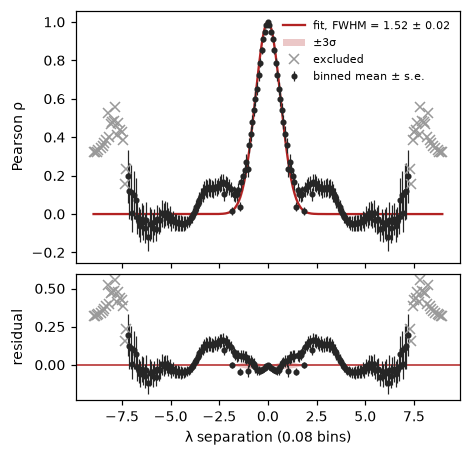

In [5]:
X_prior = ins.forward(obs)(ins.sample_amplitudes(5000, rng))     # noiseless observations of prior samples

fit = pt.fit_kernel_width(X_prior, obs["x_axis"], normalise=True)
FWHM = fit["fwhm"]
print(f"kernel FWHM = {FWHM:.3f} ± {fit['fwhm_err']:.3f} in λ")
plotting.kernel_fit(fit, xlabel="λ separation");

The correlation falls off over about the width of one band, as a point moves with its neighbours because they sit
under the same bands. The correlation matrix shows this as a band along the diagonal, where the 4 filters are the
coarse cells at the bottom left and the two spectrographs are the fine ones.

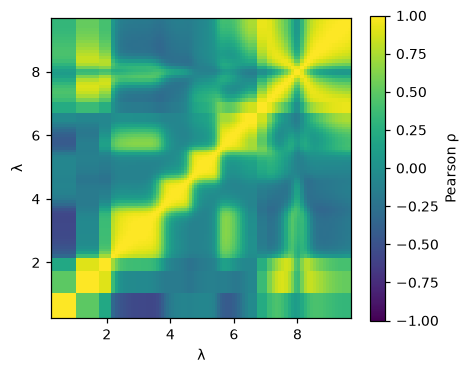

In [6]:
plotting.correlation_matrix(fit, xlabel="λ");

## Step 2: how far to perturb

For a centre point $m$ and magnitudes $\boldsymbol\xi$, the perturbed samples are
$X'_m = \mathbf{1}_K x^\star + \boldsymbol\xi\, \boldsymbol\sigma \odot \mathbf{w}(\varepsilon, m)$, where $\mathbf w$
is the Gaussian window of FWHM $\varepsilon$. Here every point moves by its **own** noise (`scale="own"`), as the noise
jumps between the filters and the spectrograph bins. The default, `scale="centre"`, instead moves every point by the
noise of the centre point, which keeps the window smooth. `batch_size=1` hands `f` one perturbed observation per call,
for retrievals that can't take a batch.

First we perturb every centre over a deliberately wide range of magnitudes, $\pm$`XI_EXPLORE`. If the limit found
below is at the edge of this range, widen it.

In [7]:
XI_EXPLORE = 5    # in sigma; widen this if the limit below comes out at the edge
perturber = pt.Perturber(f, obs["x_axis"], obs["sigma"], FWHM, scale="own", batch_size=1)
wide = perturber(obs["y"], pt.magnitude_grid(xi_max=XI_EXPLORE, n=41))

We then ask the retrieval itself. Each of its answers is put back through the forward model, and we measure how much
of the perturbation that best fit reproduces, which we call the **fraction fitted**,

$$F = \frac{\Delta\text{fit} \cdot \Delta x}{\Delta x \cdot \Delta x}, \qquad \Delta x = X' - x^\star, \quad \Delta\text{fit} = g(f(X')) - g(f(x^\star)),$$

where both are in units of the noise. $F = 1$ means the fit explains the whole perturbation as signal, and $F = 0$
means it treats it as noise. While $F$ stays within `tol` of its value at the smallest $\xi$, the retrieval is
treating a bigger perturbation the same way it treats a small one, and we count the perturbed sample as **in
distribution** (inside the black line).

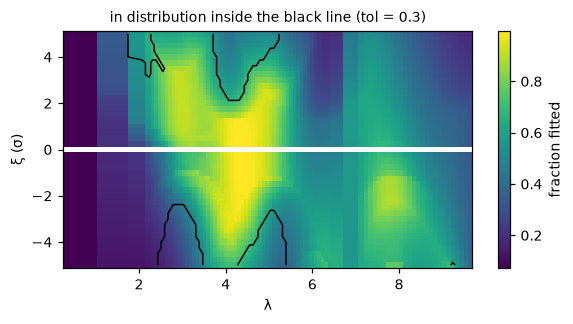

In [8]:
curve = pt.in_distribution_curve(wide, ins.forward(obs), tol=0.3)
plotting.ood_map(curve, wide, xlabel="λ");

The curve summarises the map, giving the fraction of columns still inside the black line at each magnitude.
`max_magnitude` then reads off the largest $|\xi|$ at which at least 95 per cent of them are.

in distribution up to |xi| = 2.25 sigma


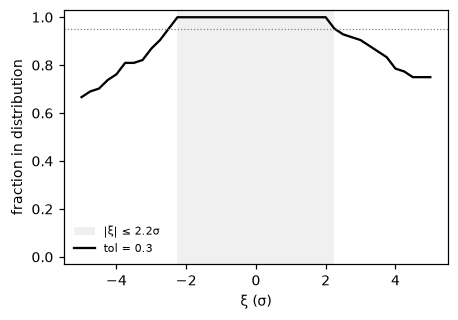

In [9]:
XI_MAX = pt.max_magnitude(curve)
print(f"in distribution up to |xi| = {XI_MAX:g} sigma")
plotting.in_distribution(curve);

## Step 3: perturb the observation

We only perturb as far as step 2 says the retrieval can be trusted, $\pm$`XI_MAX`. The budget needs to know where each
response crosses the target, so we use a fine grid, with steps of 0.1σ.

Each perturbed sample costs one least-squares fit. At $\xi = 0$ every centre's sample is just the observation itself,
so that one fit is shared, giving $M \times (K - 1) + 1$ fits in all, which takes a few seconds.

In [10]:
xi = pt.magnitude_grid(XI_MAX, int(round(2 * XI_MAX / 0.1)) + 1)   # steps of 0.1 sigma
result = perturber(obs["y"], xi)
print("response:", result.response.shape, "(centres, magnitudes, outputs)")

response: (84, 47, 5) (centres, magnitudes, outputs)


## Step 4: the response against the target

The **callouts** (`plotting.callouts`) show the response-gradient map of $a_4$. Each column is a window centred at one
point, and each row is the slope of $a_4$'s response between two neighbouring magnitudes. Purple means that raising
the spectrum there raises $a_4$, and orange means that it lowers it. Above the map are the columns with the most
positive and most negative importance, each with the straight line that the importance alone would predict (dashed).

With `threshold=TARGET`, any response bigger than the target is blacked out, and the black line in each callout marks
where the response first reaches it, on either side of zero (`result.crossing(TARGET)`). The blacked-out region shows
everywhere that a single exposure is not good enough.

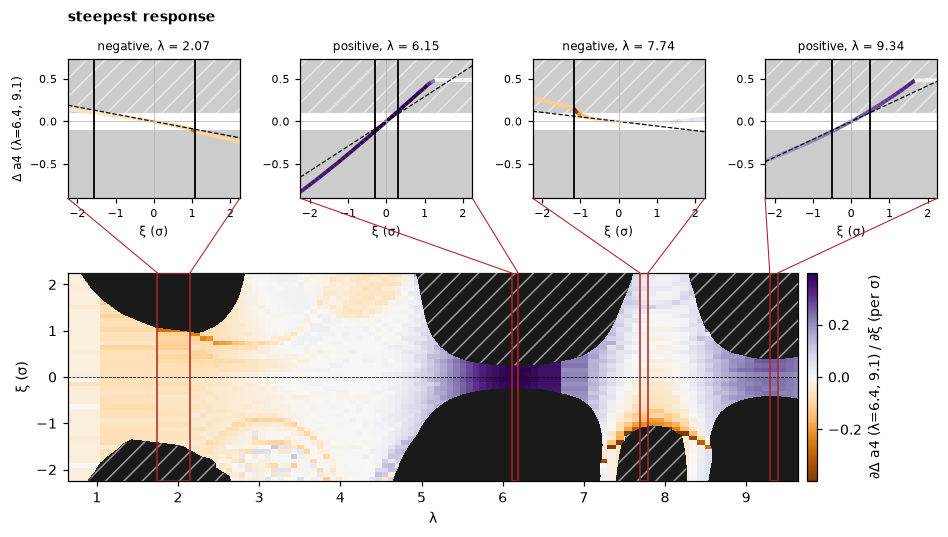

In [11]:
plotting.callouts(result, output=P, threshold=TARGET, names=ins.NAMES, xlabel="λ", n_positive=2, n_negative=2,
                  n_nonlinear=0);

## Step 5: the uncertainty budget

`result.crossing(TARGET)` has shape `(M, 2, P)`. For every centre, it gives the first magnitude below zero and the
first above zero at which $|\Delta a_k|$ reaches the target, or NaN where it never does. The budget takes the nearer of
the two, so that neither a rise nor a fall of the region moves $a_4$ too far, and turns it into a noise, as the largest
noise point $m$ can have is $|\xi_c|\,\sigma_m$. `result.nonlinearity` (the bend that the callouts pick out) and
`result.importance` are also available as arrays, if you need them for anything downstream.

Averaging $N$ exposures divides every point's noise by $\sqrt N$, so point $m$ needs $N_m = \lceil 1/\xi_c^2 \rceil$
exposures. One exposure of a spectrograph reads all of its bins at once, so each spectrograph needs as many exposures
as its most demanding bin.

A bin whose response never reaches the target within $\pm$`XI_MAX` is given one exposure. This is an assumption, as
the perturbation can't see past `XI_MAX`, and a bin that would cross somewhere between `XI_MAX` and 1σ would really
need 2.

In [12]:
cross = result.crossing(TARGET)[:, :, P]                 # (M, 2): first xi below and above zero
xi_c = np.fmin(np.abs(cross[:, 0]), np.abs(cross[:, 1]))  # the nearer side, or NaN if it never crosses within ±XI_MAX
allowed = xi_c * obs["sigma"]                             # the largest noise each point can have
need = np.where(np.isnan(xi_c), 1, np.ceil(1 / xi_c ** 2)).astype(int)
ELEMENTS = list(dict.fromkeys(obs["element"]))            # in wavelength order
exposures = {e: int(need[obs["element"] == e].max()) for e in ELEMENTS}

print(f"{'instrument':>10} {'points':>6} {'crossed':>7} {'tightest allowed noise':>22} {'exposures':>9}")
for e in ELEMENTS:
    g = obs["element"] == e
    lim = f"{np.nanmin(allowed[g]):.3g}" if np.isfinite(allowed[g]).any() else "any"
    print(f"{e:>10} {g.sum():>6} {np.isfinite(xi_c[g]).sum():>7} {lim:>22} {exposures[e]:>9}")
print(f"{sum(exposures.values())} exposures in all")

instrument points crossed tightest allowed noise exposures
        f0      1       0                    any         1
        f1      1       1                 0.0685         1
        f2      1       1                 0.0753         1
        S1     54      31                 0.0527        12
        f3      1       1                 0.0196         5
        S2     26      26                 0.0554         5
25 exposures in all


The top panel shows every point's current noise (filled) against the most it can have (open). A point whose response
crosses the target inside 1σ ($\xi_c < 1$) needs less noise than it has, so its open marker sits below the filled one,
and it needs $N_m = \lceil 1/\xi_c^2 \rceil$ exposures to get there. A point that only crosses beyond 1σ already has
room to spare (open above filled), so it needs one exposure. Points that never cross within $\pm$`XI_MAX` have no open
marker, and are also given one exposure. The bottom panel shows, on a log scale, the exposures each point needs, with a
line over each instrument's range at the number it gets, which is set by its most demanding bin.

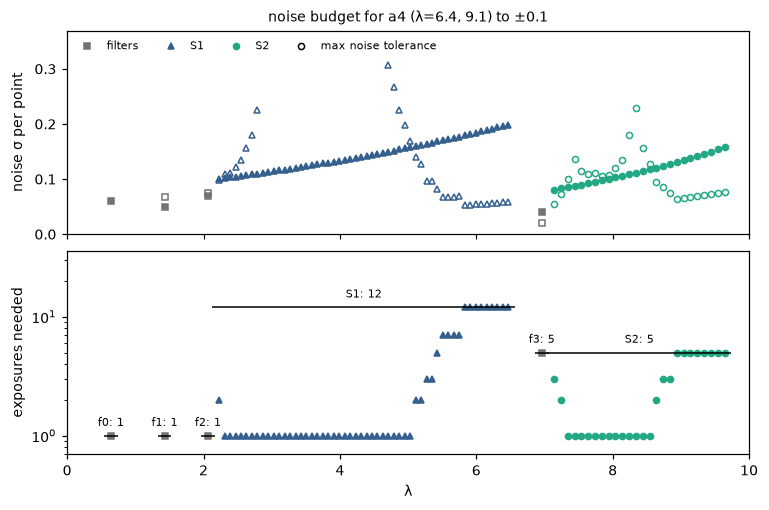

In [13]:
def by_element(ax, values, filled=True, colour=None, **kw):
    # one marker per point, using each element's colour and marker (squares for filters, triangles for S1, dots for S2)
    for e in ELEMENTS:
        g = obs["element"] == e
        c, m = (FILTER_C, "s") if e.startswith("f") else (SPEC_C[e], SPEC_M[e])
        c = colour or c
        ax.plot(obs["x_axis"][g], values[g], m, ms=4, color=c, mfc=c if filled else "none",
                label=None if not filled else ("filters" if e == "f0" else None) if e.startswith("f") else e, **kw)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw=dict(hspace=0.08))
by_element(a1, obs["sigma"])
by_element(a1, allowed, filled=False)
a1.plot([], [], "o", mfc="none", color="k", ms=4, label="max noise tolerance")

a1.set_ylabel("noise σ per point")
a1.legend(fontsize=7, frameon=False, ncols=4, loc="upper left")
a1.set_title(f"noise budget for {ins.NAMES[P]} to ±{TARGET}", fontsize=9)
a1.set_ylim(0, np.maximum(obs["sigma"].max(), allowed[np.isfinite(allowed)].max()) * 1.2)
by_element(a2, need)
for e in ELEMENTS:
    x = obs["x_axis"][obs["element"] == e]
    a2.hlines(exposures[e], x.min() - 0.1, x.max() + 0.1, color="k", lw=1)
    a2.text(x.mean(), exposures[e] * 1.15, f"{e}: {exposures[e]}", ha="center", va="bottom", fontsize=7)
a2.set_yscale("log"); a2.set_ylim(0.7, 3 * need.max()); a2.set_ylabel("exposures needed")
a2.set_xlim(0, 10); a2.set_xlabel("λ")
fig.align_ylabels([a1, a2]);

## Checking the plan

Now we take the plan, averaging `exposures[e]` exposures of each instrument so that its noise (and this noise
realisation) is divided by $\sqrt{N}$. We then refit, and compare the retrieved posteriors. On the left are the corner
plots, with one exposure of everything in grey and the plan in red, against the truth (black lines). On the right is
the posterior of $a_4$ on its own, as a histogram of draws from each, with the requirement (the plan's answer
$\pm$ `TARGET`) shaded. The plan succeeds if its $\pm 1\sigma$ (dotted) sits inside the shaded band.

a4 (λ=6.4, 9.1): ± 0.195 from one exposure -> ± 0.081 from the plan (target ± 0.1)


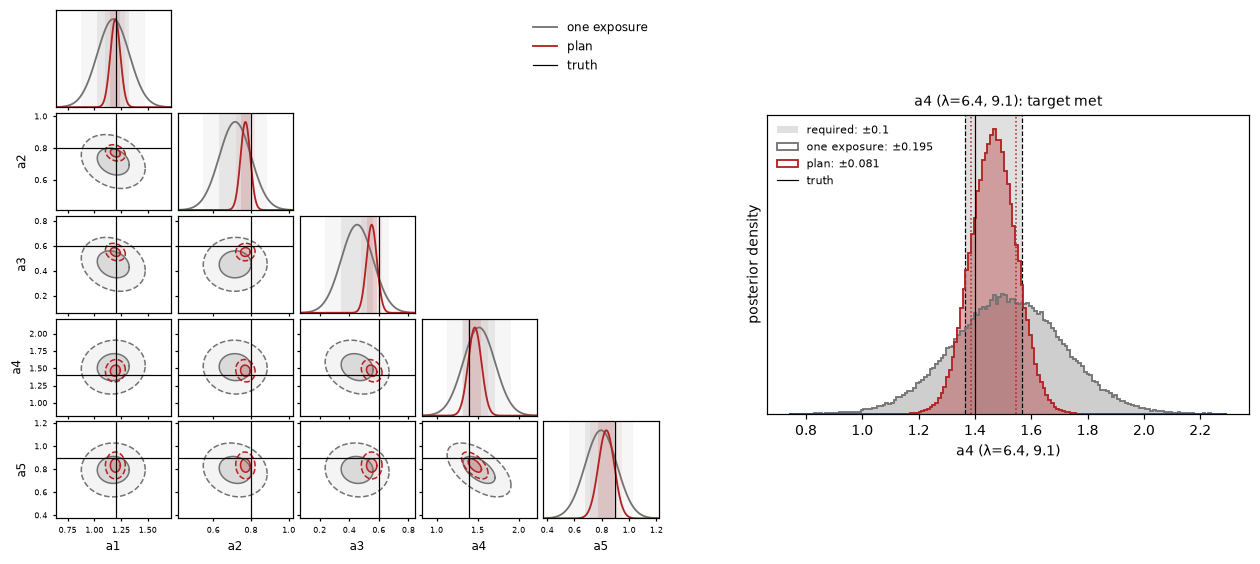

In [14]:
obs_plan = ins.observe(full, A_TRUE, exposures)
f_plan = ins.retrieval(obs_plan)
cov_plan = ins.covariance(obs_plan, f_plan.best)
sig_plan = np.sqrt(np.diag(cov_plan))
print(f"{ins.NAMES[P]}: ± {sig[P]:.3f} from one exposure -> ± {sig_plan[P]:.3f} from the plan (target ± {TARGET})")

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 0.8], wspace=0.2)
corner(fig, gs[0], [("one exposure", f.best, cov, "0.45"), ("plan", f_plan.best, cov_plan, "firebrick")])

ax = fig.add_subplot(gs[1].subgridspec(3, 1, height_ratios=[0.5, 2, 0.5])[1])
draws = np.random.default_rng(0)
bins = np.linspace(f.best[P] - 4 * sig[P], f.best[P] + 4 * sig[P], 160)
ax.axvspan(f_plan.best[P] - TARGET, f_plan.best[P] + TARGET, color="k", alpha=0.12, lw=0,
           label=f"required: ±{TARGET}")
for edge in (-TARGET, TARGET):
    ax.axvline(f_plan.best[P] + edge, color="k", ls="--", lw=0.8)
for label, m, s_, c in (("one exposure", f.best[P], sig[P], "0.45"), ("plan", f_plan.best[P], sig_plan[P], "firebrick")):
    d = draws.normal(m, s_, 100_000)
    ax.hist(d, bins, density=True, histtype="stepfilled", color=c, alpha=0.35, lw=0)
    ax.hist(d, bins, density=True, histtype="step", color=c, lw=1.2,
            label=f"{label}: ±{s_:.3f}")
ax.axvline(f_plan.best[P] - sig_plan[P], color="firebrick", ls=":", lw=1)
ax.axvline(f_plan.best[P] + sig_plan[P], color="firebrick", ls=":", lw=1)
ax.axvline(A_TRUE[P], color="k", lw=0.8, label="truth")
ax.set_xlabel(ins.NAMES[P]); ax.set_ylabel("posterior density"); ax.set_yticks([])
ax.set_title(f"{ins.NAMES[P]}: target met" if sig_plan[P] <= TARGET else f"{ins.NAMES[P]}: target missed", fontsize=9)
ax.legend(fontsize=7, frameon=False, loc="upper left");

The retrieved error bar on $a_4$ comes out inside the target, with room to spare. This is because the budget is a
stricter requirement than the error bar, as it asks that no *single region* of the observation, moving coherently by
one σ across a whole kernel width, shifts $a_4$ by more than the target. Independent noise in each bin partly cancels
out inside a window, so the retrieved σ is smaller. The budget is best read as the requirement for noise that is
correlated over about one kernel width (e.g. a systematic that drifts with $\lambda$), and as a safe upper bound for
white noise. It is also only a quick, one-pass estimate, as the exposures change how the retrieval weighs each
instrument, and with it the response, so the budget is only exact for small changes to the instrument.

**Caveats.** The budget is for a *region* the width of the kernel, not for one point on its own. It is also tied to
this one truth and noise realisation, so for real planning you should repeat it over plausible truths and noise draws.
Finally, the crossing is the first grid point past the target, so it is at most one grid step (0.1σ here) further out
than the true crossing.

## Using it on your own retrieval

```python
import perturb as pt
fit = pt.fit_kernel_width(X_prior, x_axis)                                          # 1. kernel width
perturber = pt.Perturber(f, x_axis, sigma, fit["fwhm"], scale="own", batch_size=1)
xi_max = pt.max_magnitude(pt.in_distribution_curve(perturber(x, pt.magnitude_grid(5, 41)), forward))  # 2. how far
result = perturber(x, pt.magnitude_grid(xi_max, 61))                                # 3. perturb, as far as trusted
cross = result.crossing(target)[:, :, p]                                            # 4. (M, 2), NaN: not within ±xi_max
xi_c = np.fmin(np.abs(cross[:, 0]), np.abs(cross[:, 1]))
allowed = xi_c * sigma                                                              # 5. noise budget per point
exposures = np.where(np.isnan(xi_c), 1, np.ceil(1 / xi_c ** 2))                     #    ... and exposures
```